# 01 - Explore the data and compare the models

January 2025 NYC Yellow Taxi trips. This notebook checks the raw data, explains the cleaning
rules and features used in `src/`, and reads the training runs back from MLflow.
Run `uv run python -m src.train` and `uv run python -m src.tune` first.

In [1]:
import os
os.chdir("..") if os.path.basename(os.getcwd()) == "notebooks" else None
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"

import matplotlib.pyplot as plt
import pandas as pd

from src import data
from src.features import FEATURES, build_features

raw = data.load()
print(f"{len(raw):,} raw trips, {raw.shape[1]} columns")
raw.head(3)

3,475,226 raw trips, 20 columns


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,1,2025-01-01 00:18:38,2025-01-01 00:26:59,1.0,1.6,1.0,N,229,237,1,10.0,3.5,0.5,3.00,0.0,1.0,18.00,2.5,0.0,0.0
1,1,2025-01-01 00:32:40,2025-01-01 00:35:13,1.0,0.5,1.0,N,236,237,1,5.1,3.5,0.5,2.02,0.0,1.0,12.12,2.5,0.0,0.0
2,1,2025-01-01 00:44:04,2025-01-01 00:46:01,1.0,0.6,1.0,N,141,141,1,5.1,3.5,0.5,2.00,0.0,1.0,12.10,2.5,0.0,0.0


## The target: trip duration in minutes

In [2]:
duration = (raw.tpep_dropoff_datetime - raw.tpep_pickup_datetime).dt.total_seconds() / 60
summary = duration.describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).round(2)
print(summary.to_string())
print(f"negative durations: {(duration < 0).sum():,}; over 24 hours: {(duration > 1440).sum():,}")

count    3475226.00
mean          15.02
std           38.71
min       -51472.32
1%             0.67
5%             3.37
50%           11.70
95%           36.20
99%           58.92
max         5626.32
negative durations: 124; over 24 hours: 20


## Cleaning rules (`src/data.py`)

Keep trips of 1-60 minutes, distance above 0 and at most 100 miles, and pickups inside January 2025.

In [3]:
checks = {
    "duration 1-60 min": duration.between(1, 60),
    "distance > 0": raw.trip_distance > 0,
    "distance <= 100": raw.trip_distance <= 100,
    "pickup in January": raw.tpep_pickup_datetime.dt.month.eq(1) & raw.tpep_pickup_datetime.dt.year.eq(2025),
}
print(pd.Series({k: f"{v.mean():.2%}" for k, v in checks.items()}).to_string())
clean = data.clean(raw)
print(f"kept {len(clean):,} of {len(raw):,} trips ({len(clean) / len(raw):.1%})")

duration 1-60 min     97.93%
distance > 0          97.38%
distance <= 100      100.00%
pickup in January    100.00%


kept 3,339,084 of 3,475,226 trips (96.1%)


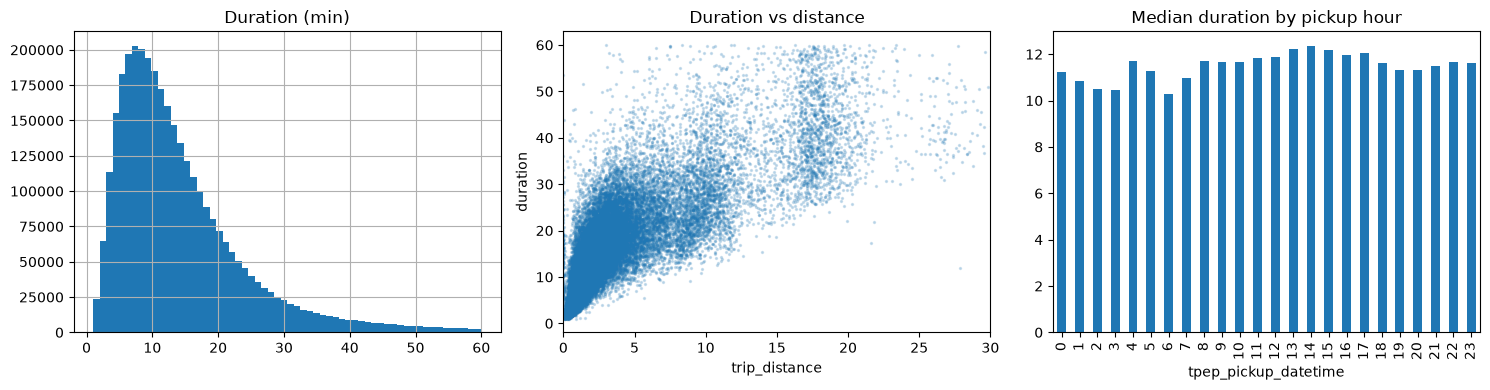

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
clean[data.TARGET].hist(bins=60, ax=axes[0]); axes[0].set_title("Duration (min)")
clean.sample(50_000, random_state=0).plot.scatter("trip_distance", data.TARGET, s=2, alpha=0.2, ax=axes[1])
axes[1].set_xlim(0, 30); axes[1].set_title("Duration vs distance")
by_hour = clean.groupby(clean.tpep_pickup_datetime.dt.hour)[data.TARGET].median()
by_hour.plot.bar(ax=axes[2]); axes[2].set_title("Median duration by pickup hour")
plt.tight_layout()

## Features (`src/features.py`)

Only what is known when a trip starts: pickup and dropoff zone, distance, pickup hour and weekday.
`fare_amount`, `tip_amount` and `total_amount` are known only after the trip, so they would leak the target.

In [5]:
X = build_features(clean)
print(FEATURES)
print(X.assign(duration=clean[data.TARGET]).corr(numeric_only=True)["duration"].round(3).to_string())

['PULocationID', 'DOLocationID', 'trip_distance', 'pickup_hour', 'pickup_weekday']
PULocationID     -0.118
DOLocationID     -0.103
trip_distance     0.800
pickup_hour       0.002
pickup_weekday   -0.018
duration          1.000


## Runs in MLflow: baselines vs tuned (RandomForest and HistGradientBoosting)

In [6]:
import mlflow
from src.train import EXPERIMENT, TRACKING_URI

mlflow.set_tracking_uri(TRACKING_URI)
runs = mlflow.search_runs(experiment_names=[EXPERIMENT])
runs = runs[runs["tags.mlflow.runName"].isin(["rf-baseline", "rf-tuned", "hgb-tuned"])]
cols = ["tags.mlflow.runName", "metrics.rmse", "metrics.mae", "metrics.baseline_mean_rmse",
        "metrics.fit_seconds", "params.n_estimators", "params.max_depth", "params.min_samples_leaf",
        "params.max_features", "params.train_rows", "params.validation_rows"]
comparison = (runs.sort_values("start_time").drop_duplicates("tags.mlflow.runName", keep="last")[
    [c for c in cols if c in runs.columns]].set_index("tags.mlflow.runName"))
comparison.round(3)

,metrics.rmse,metrics.mae,metrics.baseline_mean_rmse,metrics.fit_seconds,params.n_estimators,params.max_depth,params.min_samples_leaf,params.max_features,params.train_rows,params.validation_rows
tags.mlflow.runName,,,,,,,,,,
rf-baseline,4.103,2.756,9.78,9.851,100,20,10,NaN,500000,667817
rf-tuned,4.034,2.708,9.78,6.662,100,26,3,0.6,500000,667817
hgb-tuned,3.774,2.521,NaN,18.886,NaN,NaN,59,NaN,500000,NaN


In [7]:
all_runs = mlflow.search_runs(experiment_names=[EXPERIMENT])
searches = (all_runs[all_runs["tags.mlflow.runName"].str.startswith("optuna-search")]
            .sort_values("start_time").drop_duplicates("tags.mlflow.runName", keep="last"))
for _, search in searches.iterrows():
    trials = all_runs[all_runs["tags.mlflow.parentRunId"] == search.run_id]
    print(f"{search['tags.mlflow.runName']}: {len(trials)} trials, best RMSE {trials['metrics.rmse'].min():.3f}, "
          f"worst {trials['metrics.rmse'].max():.3f}")

optuna-search: 20 trials, best RMSE 4.136, worst 4.333
optuna-search-hgb: 20 trials, best RMSE 3.866, worst 4.015


## More approaches: linear vs RandomForest vs HistGradientBoosting, and February 2025

From `uv run python -m src.compare`: the same 500,000 training rows, scored on the January validation set and on every cleaned February 2025 trip (a month no model saw).

In [8]:
compare = all_runs[all_runs["tags.mlflow.runName"].str.startswith("compare-")]
compare = compare.sort_values("start_time").drop_duplicates("tags.mlflow.runName", keep="last")
cols = {"metrics.jan_rmse": "RMSE Jan", "metrics.feb_rmse": "RMSE Feb", "metrics.jan_mae": "MAE Jan",
        "metrics.model_mb": "size MB", "metrics.fit_seconds": "fit s", "metrics.jan_ms_per_1k": "ms / 1k preds"}
compare.set_index("tags.mlflow.runName")[list(cols)].rename(columns=cols).sort_values("RMSE Jan").round(3)

,RMSE Jan,RMSE Feb,MAE Jan,size MB,fit s,ms / 1k preds
tags.mlflow.runName,,,,,,
compare-hgb,3.784,3.961,2.532,8.604,12.303,2.654
compare-rf,4.103,4.270,2.756,290.970,9.485,2.063
compare-linear,5.473,5.614,3.919,0.092,0.269,0.091
